,Executed versions
Python,3.14.2
NumPy,2.5.3
pandas,3.0.6
scikit-learn,1.9.1
XGBoost,3.4.1


Rows: 10,000; predictors: 10
SHA-256: 00a5cab178a8b7cd6e9157ee71dabc236ba7f20b1832336d358b07af14ba431f


,Missing values before fill
model_year,0
origin,0
fuel_type,0
drivetrain,0
num_doors,0
engine_displacement,0
num_cylinders,0
horsepower,877
vehicle_weight,0
acceleration,264


Train / validation / test: 6000 / 2000 / 2000
Encoded training matrix: (6000, 16)
Number of encoded features: 16

QUESTION 1
|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]

Q1 answer: model_year


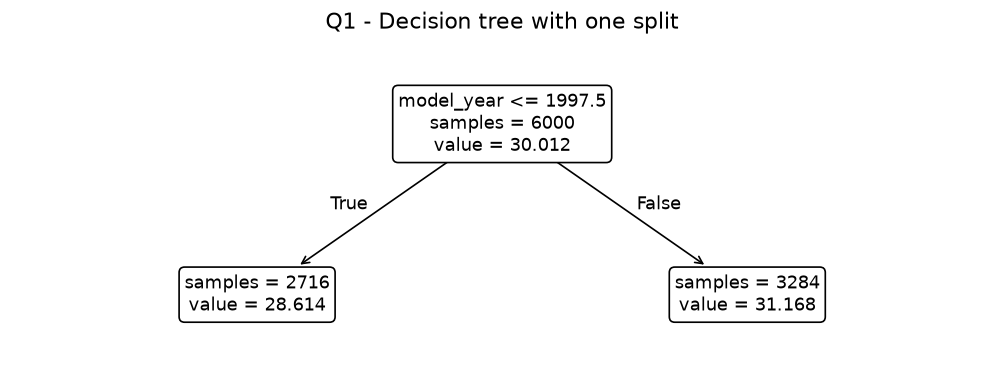


QUESTION 2
Validation RMSE: 1.833219736 mpg
Q2 answer: 1.837

QUESTION 3


,n_estimators,RMSE (mpg),RMSE (3 decimals)
0,10,1.833220,1.833
1,50,1.773988,1.774
2,100,1.769786,1.770
3,150,1.769198,1.769


Q3 answer: 150


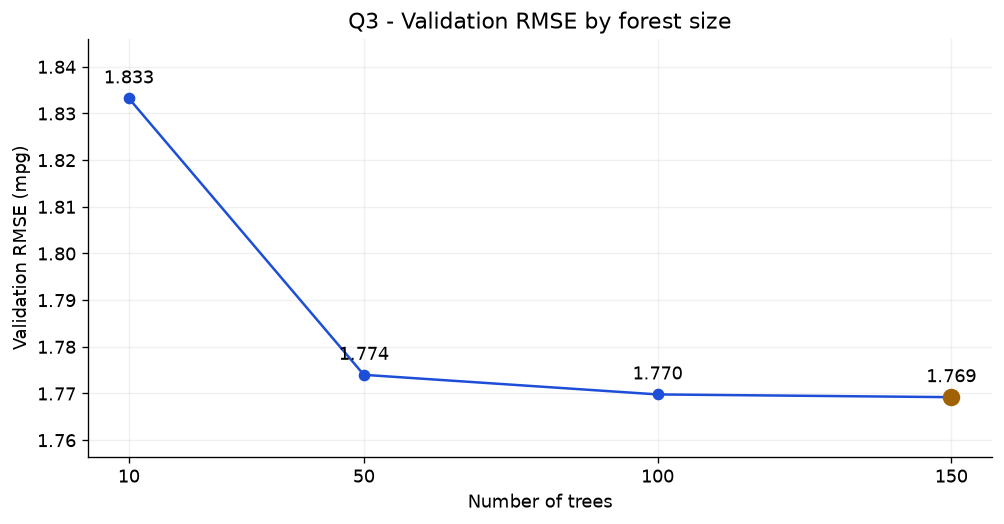


QUESTION 4


n_estimators,10,50,100,150
max_depth,,,,
10,1.782348,1.747520,1.743986,1.743716
15,1.831390,1.770883,1.767872,1.766752
20,1.837314,1.772377,1.768918,1.768476
25,1.836852,1.772123,1.768320,1.767927


,max_depth,Mean RMSE (mpg)
0,10,1.754392
1,15,1.784224
2,20,1.786771
3,25,1.786305


Q4 answer: 10


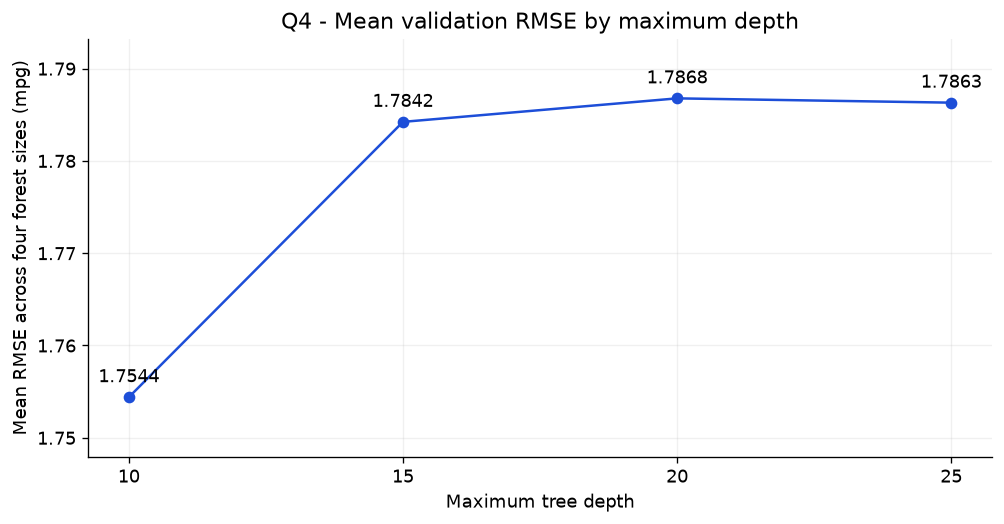


QUESTION 5


,Importance
vehicle_weight,0.203313
horsepower,0.078271
engine_displacement,0.061281
acceleration,0.054998


Q5 answer among choices: vehicle_weight
Highest importance overall: model_year (0.296107)


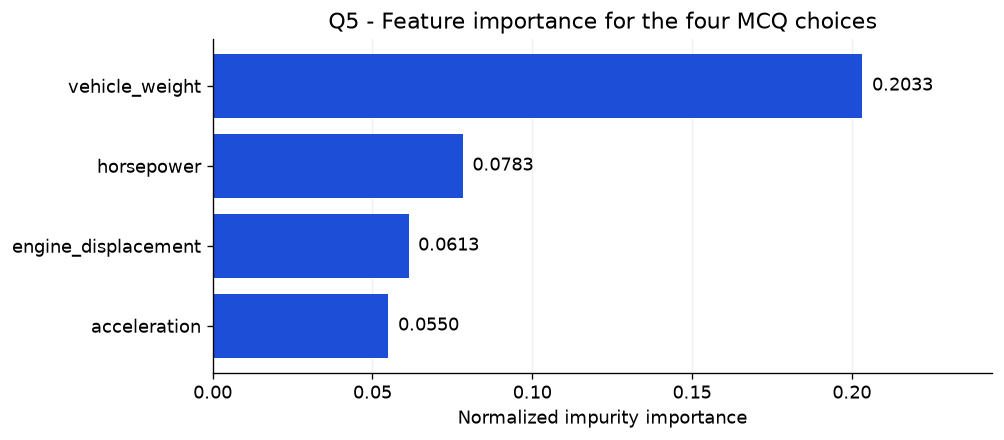


QUESTION 6


,eta,Final RMSE (mpg),Best intermediate RMSE (mpg),Best round
0,0.3,1.826458,1.732048,11
1,0.1,1.724810,1.712171,40


Q6 answer: eta = 0.1


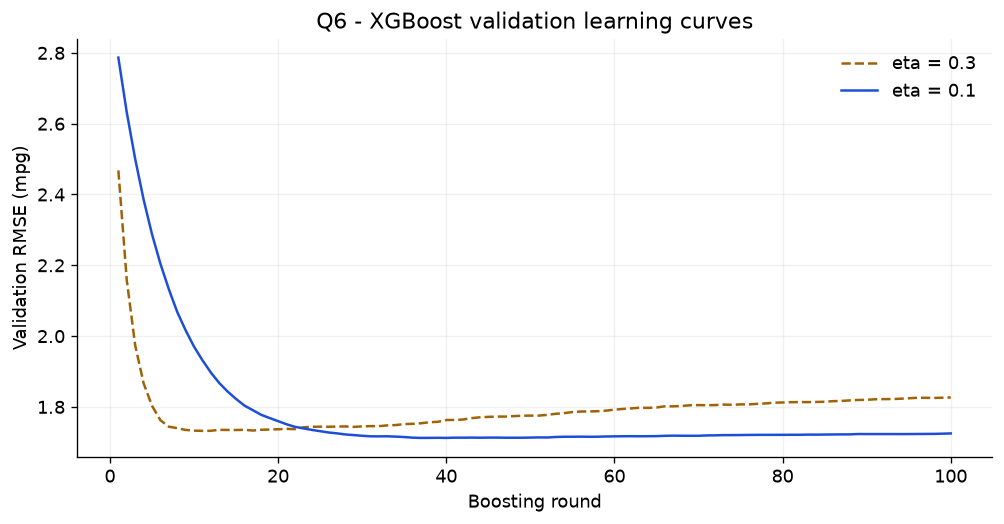

AssertionError: 

In [3]:
# ============================================================
# ML Zoomcamp 2026 - Homework 6
# Decision Trees and Ensemble Learning
# ============================================================

# If packages are missing, run this once:
# %pip install numpy pandas scikit-learn xgboost matplotlib


# ============================================================
# 1. IMPORTS
# ============================================================

from pathlib import Path
import hashlib
import io
import platform
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost as xgb

from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree


# ============================================================
# 2. CONFIGURATION
# ============================================================

plt.rcParams.update({
    'figure.figsize': (8.5, 4.5),
    'figure.dpi': 120,
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.18,
    'axes.axisbelow': True,
})

BLUE = '#1D4ED8'
GOLD = '#A16207'

TARGET = 'fuel_efficiency_mpg'

SIZES = [10, 50, 100, 150]
DEPTHS = [10, 15, 20, 25]

ARTIFACTS = Path('hw06_figures')
ARTIFACTS.mkdir(exist_ok=True)


def validation_rmse(model):
    predictions = model.predict(X_val)

    return float(
        np.sqrt(
            mean_squared_error(
                y_val,
                predictions
            )
        )
    )


# Check versions
display(
    pd.Series({
        'Python': platform.python_version(),
        'NumPy': np.__version__,
        'pandas': pd.__version__,
        'scikit-learn': sklearn.__version__,
        'XGBoost': xgb.__version__,
    }, name='Executed versions').to_frame()
)


# ============================================================
# 3. LOAD DATASET
# ============================================================

DATA_URL = (
    'https://raw.githubusercontent.com/'
    'DataTalksClub/machine-learning-zoomcamp/'
    'main/cohorts/2026/data/'
    'car_fuel_efficiency_2026.csv'
)

EXPECTED_SHA256 = (
    '00a5cab178a8b7cd6e9157ee71dabc236'
    'ba7f20b1832336d358b07af14ba431f'
)

data_path = Path(
    'car_fuel_efficiency_2026.csv'
)

if data_path.exists():

    print("Using local dataset")

    data_bytes = data_path.read_bytes()

else:

    print("Downloading dataset...")

    with urllib.request.urlopen(
        DATA_URL,
        timeout=60
    ) as response:

        data_bytes = response.read()

    data_path.write_bytes(
        data_bytes
    )


# Verify dataset
actual_sha256 = hashlib.sha256(
    data_bytes
).hexdigest()

assert actual_sha256 == EXPECTED_SHA256, (
    'Dataset differs from the verified release.'
)


# Read CSV
raw_df = pd.read_csv(
    io.BytesIO(data_bytes)
)

assert raw_df.shape == (10000, 11)

assert raw_df[TARGET].notna().all()


print(
    f'Rows: {len(raw_df):,}; '
    f'predictors: {len(raw_df.columns) - 1}'
)

print(
    f'SHA-256: {actual_sha256}'
)


display(
    raw_df
    .isna()
    .sum()
    .rename('Missing values before fill')
    .to_frame()
)


# Fill missing values with 0
df = raw_df.fillna(0)


# ============================================================
# 4. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

df_full_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=1
)

df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=1
)


assert len(df_train) == 6000
assert len(df_val) == 2000
assert len(df_test) == 2000


# Check no overlapping rows
assert set(
    df_train.index
).isdisjoint(
    df_val.index
)

assert set(
    df_full_train.index
).isdisjoint(
    df_test.index
)


# Target
y_train = df_train[
    TARGET
].to_numpy()

y_val = df_val[
    TARGET
].to_numpy()


# ============================================================
# 5. DICT VECTORIZER
# ============================================================

vectorizer = DictVectorizer(
    sparse=True
)


train_dicts = (
    df_train
    .drop(columns=TARGET)
    .to_dict(
        orient='records'
    )
)

val_dicts = (
    df_val
    .drop(columns=TARGET)
    .to_dict(
        orient='records'
    )
)


X_train = vectorizer.fit_transform(
    train_dicts
)

X_val = vectorizer.transform(
    val_dicts
)


feature_names = list(
    vectorizer
    .get_feature_names_out()
)


print(
    f'Train / validation / test: '
    f'{len(df_train)} / '
    f'{len(df_val)} / '
    f'{len(df_test)}'
)

print(
    f'Encoded training matrix: '
    f'{X_train.shape}'
)

print(
    f'Number of encoded features: '
    f'{len(feature_names)}'
)

assert TARGET not in feature_names


# ============================================================
# QUESTION 1
# Original splitting feature
# ============================================================

stump = DecisionTreeRegressor(
    max_depth=1,
    random_state=1
)

stump.fit(
    X_train,
    y_train
)


encoded_root = feature_names[
    stump.tree_.feature[0]
]


q1_answer = encoded_root.split(
    '=',
    1
)[0]


print("\n================================")
print("QUESTION 1")
print("================================")

print(
    export_text(
        stump,
        feature_names=feature_names
    )
)

print(
    f'Q1 answer: {q1_answer}'
)


# Plot tree
fig, ax = plt.subplots(
    figsize=(8.5, 3.4)
)

plot_tree(
    stump,
    feature_names=feature_names,
    impurity=False,
    filled=False,
    rounded=True,
    precision=3,
    ax=ax,
    fontsize=11
)

ax.set_title(
    'Q1 - Decision tree with one split'
)

fig.tight_layout()

fig.savefig(
    ARTIFACTS / 'q1_tree.png',
    bbox_inches='tight'
)

plt.show()


# ============================================================
# QUESTION 2
# Random Forest validation RMSE
# ============================================================

baseline_forest = RandomForestRegressor(
    n_estimators=10,
    random_state=1,
    n_jobs=-1
)

baseline_forest.fit(
    X_train,
    y_train
)


q2_rmse = validation_rmse(
    baseline_forest
)


q2_options = [
    0.1837,
    1.837,
    18.37,
    183.7
]


q2_answer = min(
    q2_options,
    key=lambda option: abs(
        option - q2_rmse
    )
)


print("\n================================")
print("QUESTION 2")
print("================================")

print(
    f'Validation RMSE: '
    f'{q2_rmse:.9f} mpg'
)

print(
    f'Q2 answer: {q2_answer}'
)


# ============================================================
# QUESTION 3
# Number of estimators
# ============================================================

size_rows = []


for n_estimators in SIZES:

    model = RandomForestRegressor(
        n_estimators=n_estimators,
        random_state=1,
        n_jobs=-1
    )

    model.fit(
        X_train,
        y_train
    )

    score = validation_rmse(
        model
    )

    size_rows.append({
        'n_estimators': n_estimators,
        'RMSE (mpg)': score,
        'RMSE (3 decimals)': round(
            score,
            3
        )
    })


size_results = pd.DataFrame(
    size_rows
)


winner = size_results.loc[
    size_results[
        'RMSE (3 decimals)'
    ].idxmin()
]


q3_answer = int(
    winner[
        'n_estimators'
    ]
)


print("\n================================")
print("QUESTION 3")
print("================================")

display(
    size_results.round(6)
)

print(
    f'Q3 answer: {q3_answer}'
)


# Q3 Plot
fig, ax = plt.subplots()


ax.plot(
    size_results[
        'n_estimators'
    ],
    size_results[
        'RMSE (mpg)'
    ],
    color=BLUE,
    marker='o'
)


ax.scatter(
    [q3_answer],
    [winner['RMSE (mpg)']],
    color=GOLD,
    s=90,
    zorder=3
)


ax.set(
    title='Q3 - Validation RMSE by forest size',
    xlabel='Number of trees',
    ylabel='Validation RMSE (mpg)',
    xticks=SIZES
)


for row in size_rows:

    ax.annotate(
        f"{row['RMSE (mpg)']:.3f}",
        (
            row['n_estimators'],
            row['RMSE (mpg)']
        ),
        xytext=(0, 9),
        textcoords='offset points',
        ha='center'
    )


ax.margins(
    y=0.2
)

fig.tight_layout()


fig.savefig(
    ARTIFACTS / 'q3_forest_size.png',
    bbox_inches='tight'
)

plt.show()


# ============================================================
# QUESTION 4
# Best max_depth
# ============================================================

depth_rows = []


for max_depth in DEPTHS:

    for n_estimators in SIZES:

        model = RandomForestRegressor(
            n_estimators=n_estimators,
            max_depth=max_depth,
            random_state=1,
            n_jobs=-1
        )

        model.fit(
            X_train,
            y_train
        )

        score = validation_rmse(
            model
        )

        depth_rows.append({
            'max_depth': max_depth,
            'n_estimators': n_estimators,
            'RMSE (mpg)': score
        })


depth_results = pd.DataFrame(
    depth_rows
)


depth_means = (
    depth_results
    .groupby(
        'max_depth',
        as_index=False
    )[
        'RMSE (mpg)'
    ]
    .mean()
)


q4_answer = int(
    depth_means.loc[
        depth_means[
            'RMSE (mpg)'
        ].idxmin(),
        'max_depth'
    ]
)


print("\n================================")
print("QUESTION 4")
print("================================")


display(
    depth_results
    .pivot(
        index='max_depth',
        columns='n_estimators',
        values='RMSE (mpg)'
    )
    .round(6)
)


display(
    depth_means
    .rename(
        columns={
            'RMSE (mpg)':
            'Mean RMSE (mpg)'
        }
    )
    .round(6)
)


print(
    f'Q4 answer: {q4_answer}'
)


# Q4 plot
fig, ax = plt.subplots()


ax.plot(
    depth_means[
        'max_depth'
    ],
    depth_means[
        'RMSE (mpg)'
    ],
    marker='o',
    color=BLUE
)


ax.set(
    title=(
        'Q4 - Mean validation RMSE '
        'by maximum depth'
    ),
    xlabel='Maximum tree depth',
    ylabel=(
        'Mean RMSE across four '
        'forest sizes (mpg)'
    ),
    xticks=DEPTHS
)


for row in depth_means.to_dict(
    orient='records'
):

    ax.annotate(
        f"{row['RMSE (mpg)']:.4f}",
        (
            row['max_depth'],
            row['RMSE (mpg)']
        ),
        xytext=(0, 9),
        textcoords='offset points',
        ha='center'
    )


ax.margins(
    y=0.2
)

fig.tight_layout()


fig.savefig(
    ARTIFACTS / 'q4_depth.png',
    bbox_inches='tight'
)

plt.show()


# ============================================================
# QUESTION 5
# Feature importance
# ============================================================

importance_model = RandomForestRegressor(
    n_estimators=10,
    max_depth=20,
    random_state=1,
    n_jobs=-1
)


importance_model.fit(
    X_train,
    y_train
)


importances = pd.Series(
    importance_model.feature_importances_,
    index=feature_names,
    name='Importance'
).sort_values(
    ascending=False
)


q5_options = [
    'vehicle_weight',
    'horsepower',
    'acceleration',
    'engine_displacement'
]


listed_importances = (
    importances
    .loc[q5_options]
    .sort_values(
        ascending=False
    )
)


q5_answer = (
    listed_importances
    .idxmax()
)


print("\n================================")
print("QUESTION 5")
print("================================")


display(
    listed_importances
    .to_frame()
    .round(6)
)


print(
    f'Q5 answer among choices: '
    f'{q5_answer}'
)


print(
    f'Highest importance overall: '
    f'{importances.idxmax()} '
    f'({importances.max():.6f})'
)


assert np.isclose(
    importances.sum(),
    1.0
)


# Plot Q5
fig, ax = plt.subplots(
    figsize=(8.5, 3.8)
)


ordered = (
    listed_importances
    .sort_values()
)


ax.barh(
    ordered.index,
    ordered.values,
    color=BLUE
)


ax.set(
    title=(
        'Q5 - Feature importance '
        'for the four MCQ choices'
    ),
    xlabel=(
        'Normalized impurity importance'
    )
)


ax.set_xlim(
    0,
    listed_importances.max() * 1.2
)


ax.grid(
    axis='y',
    visible=False
)


for index, value in enumerate(
    ordered.values
):

    ax.text(
        value + 0.003,
        index,
        f'{value:.4f}',
        va='center'
    )


fig.tight_layout()


fig.savefig(
    ARTIFACTS / 'q5_importance.png',
    bbox_inches='tight'
)

plt.show()


# ============================================================
# QUESTION 6
# XGBoost eta comparison
# ============================================================

dtrain = xgb.DMatrix(
    X_train,
    label=y_train,
    feature_names=feature_names
)


dval = xgb.DMatrix(
    X_val,
    label=y_val,
    feature_names=feature_names
)


watchlist = [
    (
        dtrain,
        'train'
    ),
    (
        dval,
        'validation'
    )
]


xgb_rows = []

histories = {}


for eta in [
    0.3,
    0.1
]:

    params = {

        'eta': eta,

        'max_depth': 6,

        'min_child_weight': 1,

        'objective':
            'reg:squarederror',

        'nthread': 8,

        'seed': 1,

        'verbosity': 1
    }


    history = {}


    model = xgb.train(
        params,
        dtrain,
        num_boost_round=100,
        evals=watchlist,
        evals_result=history,
        verbose_eval=False
    )


    scores = (
        history[
            'validation'
        ][
            'rmse'
        ]
    )


    predictions = model.predict(
        dval
    )


    final_rmse = float(
        np.sqrt(
            mean_squared_error(
                y_val,
                predictions
            )
        )
    )


    histories[
        eta
    ] = history


    xgb_rows.append({

        'eta':
            eta,

        'Final RMSE (mpg)':
            final_rmse,

        'Best intermediate RMSE (mpg)':
            min(scores),

        'Best round':
            int(
                np.argmin(
                    scores
                ) + 1
            )
    })


xgb_results = pd.DataFrame(
    xgb_rows
)


q6_answer = float(

    xgb_results.loc[

        xgb_results[
            'Final RMSE (mpg)'
        ].idxmin(),

        'eta'
    ]
)


print("\n================================")
print("QUESTION 6")
print("================================")


display(
    xgb_results.round(6)
)


print(
    f'Q6 answer: eta = '
    f'{q6_answer}'
)


# Q6 plot
fig, ax = plt.subplots()


ax.plot(
    range(1, 101),
    histories[
        0.3
    ][
        'validation'
    ][
        'rmse'
    ],
    label='eta = 0.3',
    color=GOLD,
    linestyle='--'
)


ax.plot(
    range(1, 101),
    histories[
        0.1
    ][
        'validation'
    ][
        'rmse'
    ],
    label='eta = 0.1',
    color=BLUE,
    linestyle='-'
)


ax.set(
    title=(
        'Q6 - XGBoost validation '
        'learning curves'
    ),
    xlabel='Boosting round',
    ylabel='Validation RMSE (mpg)'
)


ax.legend(
    frameon=False
)


fig.tight_layout()


fig.savefig(
    ARTIFACTS / 'q6_xgboost.png',
    bbox_inches='tight'
)

plt.show()


# ============================================================
# FINAL ANSWERS
# ============================================================

answers = pd.DataFrame([

    {
        'Question': 1,
        'Answer': q1_answer
    },

    {
        'Question': 2,
        'Answer': str(q2_answer)
    },

    {
        'Question': 3,
        'Answer': str(q3_answer)
    },

    {
        'Question': 4,
        'Answer': str(q4_answer)
    },

    {
        'Question': 5,
        'Answer': q5_answer
    },

    {
        'Question': 6,
        'Answer': str(q6_answer)
    }

])


expected = [

    'model_year',

    '1.837',

    '100',

    '10',

    'vehicle_weight',

    '0.1'
]


assert (
    answers
    .Answer
    .tolist()
    ==
    expected
)


print("\n================================")
print("FINAL ANSWERS")
print("================================")


display(
    answers.set_index(
        'Question'
    )
)


print(
    'All six answers reproduced successfully.'
)